import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df=pd.read_parquet('/glade/campaign/cisl/aiml/ai2es/winter_ptypes/ptype_qc/mPING_hourafter_interpolated_QC3.parquet', columns=['datetime','report_count']); x=df[(df.datetime>='2021-11-24') & (df.datetime<'2022-04-01')]; 
print('Valid rows:', len(x)); print('Total mPING reports:', x.report_count.sum())

Valid rows: 218428
Total mPING reports: 281920


In [3]:
mping_path = "/glade/campaign/cisl/aiml/ai2es/winter_ptypes/ptype_qc/mPING_hourafter_interpolated_QC3.parquet"

In [4]:
import pandas as pd

# Load only the columns we need
df = pd.read_parquet(
    mping_path,
    columns=["datetime", "lat", "lon", "report_count"]
)

# Restrict to the study period
mping = df[
    (df["datetime"] >= "2021-12-01") &
    (df["datetime"] < "2022-04-01")
].copy()

# Quick look
display(mping.head())

print("Number of rows:", len(mping))
print("Total mPING reports:", mping["report_count"].sum())

print("\nTime range:")
print("Min:", mping["datetime"].min())
print("Max:", mping["datetime"].max())

print("\nLatitude range:")
print("Min:", mping["lat"].min())
print("Max:", mping["lat"].max())

print("\nLongitude range:")
print("Min:", mping["lon"].min())
print("Max:", mping["lon"].max())

print("\nMissing values:")
print(mping[["datetime", "lat", "lon"]].isna().sum())

,datetime,lat,lon,report_count
0,2022-03-02 01:00:00,40.686584,-80.462463,1
1,2022-03-02 01:00:00,41.687332,-70.232758,1
6,2022-03-02 01:00:00,42.598061,-71.762939,1
7,2022-03-02 01:00:00,41.855820,-72.410950,2
13,2022-03-02 01:00:00,42.711250,-73.652008,1


Number of rows: 212474
Total mPING reports: 274908

Time range:
Min: 2021-12-01 00:00:00
Max: 2022-03-31 23:00:00

Latitude range:
Min: 16.281
Max: 55.5929

Longitude range:
Min: -139.85612
Max: -57.381073

Missing values:
datetime    0
lat         0
lon         0
dtype: int64


In [5]:


df = pd.read_parquet(
    mping_path,
    columns=[
        "datetime", "lat", "lon", "report_count",
        "ra_percent", "sn_percent", "fzra_percent", "pl_percent",
        "percent_max"
    ]
)

# Study period
mping = df[
    (df["datetime"] >= "2021-12-01") &
    (df["datetime"] < "2022-04-01")
].copy()

display(mping.head(20))

,datetime,lat,lon,report_count,ra_percent,sn_percent,fzra_percent,pl_percent,percent_max
0,2022-03-02 01:00:00,40.686584,-80.462463,1,1.0,0.0,0.0,0.0,ra_percent
1,2022-03-02 01:00:00,41.687332,-70.232758,1,1.0,0.0,0.0,0.0,ra_percent
6,2022-03-02 01:00:00,42.598061,-71.762939,1,1.0,0.0,0.0,0.0,ra_percent
7,2022-03-02 01:00:00,41.855820,-72.410950,2,1.0,0.0,0.0,0.0,ra_percent
13,2022-03-02 01:00:00,42.711250,-73.652008,1,1.0,0.0,0.0,0.0,ra_percent
15,2022-03-02 01:00:00,40.673992,-80.308990,3,1.0,0.0,0.0,0.0,ra_percent
16,2022-03-02 01:00:00,43.489021,-76.531219,2,0.5,0.5,0.0,0.0,ra_percent
17,2022-03-02 01:00:00,42.328259,-76.588867,6,1.0,0.0,0.0,0.0,ra_percent
19,2022-03-02 01:00:00,41.342751,-76.141388,1,1.0,0.0,0.0,0.0,ra_percent
25,2022-03-02 02:00:00,41.855820,-72.410950,1,1.0,0.0,0.0,0.0,ra_percent


In [6]:
print(mping["percent_max"].value_counts(dropna=False))

percent_max
sn_percent      115186
ra_percent       81190
pl_percent        9182
fzra_percent      6916
Name: count, dtype: int64


In [7]:


# ---------------------------------------------------------
# Load data
# ---------------------------------------------------------
df = pd.read_parquet(
    mping_path,
    columns=[
        "datetime",
        "report_count",
        "sn_percent",
        "ra_percent",
        "pl_percent",
        "fzra_percent"
    ]
)

# Study period
mping = df[
    (df["datetime"] >= "2021-12-01") &
    (df["datetime"] < "2022-04-01")
].copy()

# ---------------------------------------------------------
# Check percentage values
# ---------------------------------------------------------
pct_cols = [
    "sn_percent",
    "ra_percent",
    "pl_percent",
    "fzra_percent"
]

print(mping[pct_cols].describe())

          sn_percent     ra_percent     pl_percent   fzra_percent
count  212474.000000  212474.000000  212474.000000  212474.000000
mean        0.536696       0.376242       0.050956       0.036106
std         0.492285       0.480664       0.205379       0.180177
min         0.000000       0.000000       0.000000       0.000000
25%         0.000000       0.000000       0.000000       0.000000
50%         1.000000       0.000000       0.000000       0.000000
75%         1.000000       1.000000       0.000000       0.000000
max         1.000000       1.000000       1.000000       1.000000


In [8]:
# Fill missing percentages with zero
mping[pct_cols] = mping[pct_cols].fillna(0)

# Determine whether percentages are stored as 0-100 or 0-1
max_pct = mping[pct_cols].max().max()

if max_pct <= 1.0:
    divisor = 1.0
else:
    divisor = 100.0

print("Percentage divisor:", divisor)

# ---------------------------------------------------------
# Recover approximate number of reports in each class
# ---------------------------------------------------------
class_counts = pd.Series({
    "Snow":
        (mping["report_count"] * mping["sn_percent"] / divisor).sum(),

    "Rain":
        (mping["report_count"] * mping["ra_percent"] / divisor).sum(),

    "Ice Pellet":
        (mping["report_count"] * mping["pl_percent"] / divisor).sum(),

    "Freezing Rain":
        (mping["report_count"] * mping["fzra_percent"] / divisor).sum()
})

total_classified = class_counts.sum()

class_percent = 100 * class_counts / total_classified

summary = pd.DataFrame({
    "Reports": class_counts.round().astype(int),
    "Percent": class_percent.round(2)
})

display(summary)

print(f"Total classified reports: {total_classified:,.0f}")
print(f"Total report_count: {mping['report_count'].sum():,.0f}")

Percentage divisor: 1.0


,Reports,Percent
Snow,146606,53.33
Rain,100380,36.51
Ice Pellet,17034,6.20
Freezing Rain,10888,3.96


Total classified reports: 274,908
Total report_count: 274,908


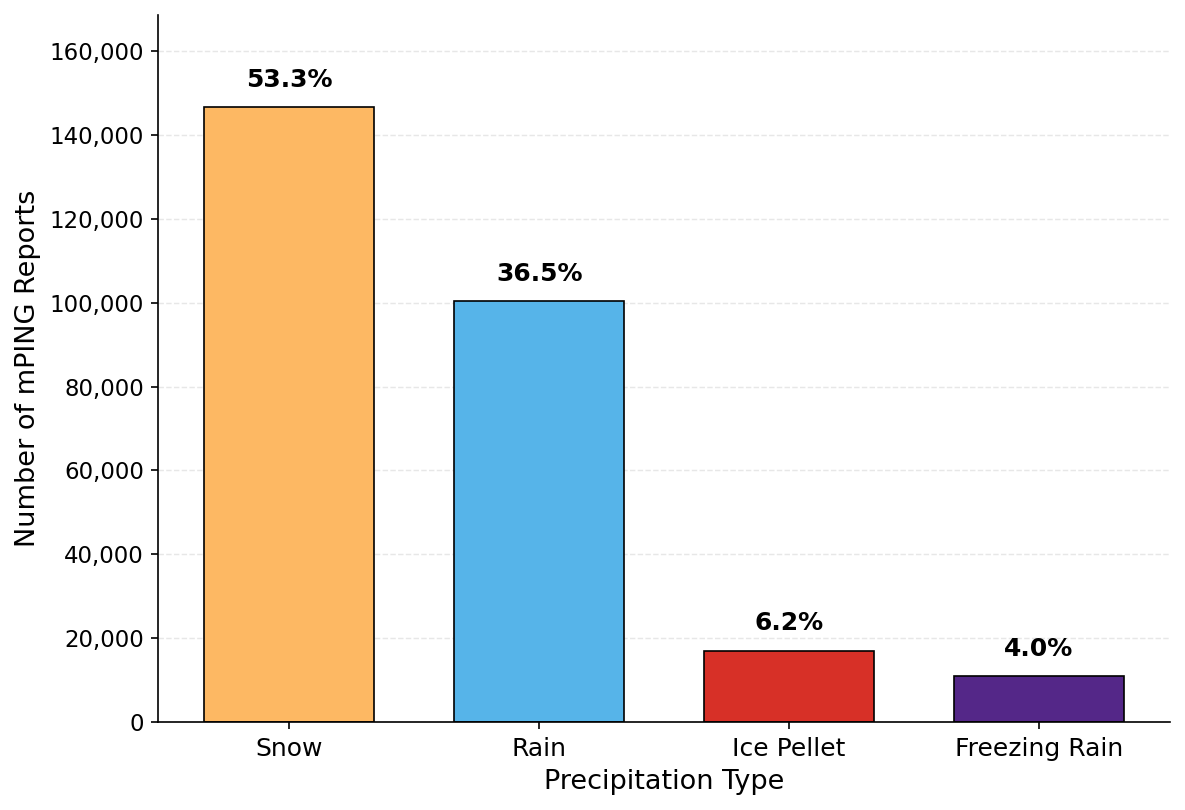

In [11]:
# ---------------------------------------------------------
# Publication-style plot
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5.5), dpi=150)

colors = [
     '#FDB863',   # Snow
    '#56B4E9',   # Rain
    '#d73027',   # Ice Pellet
   '#542788'    # Freezing Rain
]

bars = ax.bar(
    class_counts.index,
    class_counts.values,
    color=colors,
    width=0.68,
    edgecolor="black",
    linewidth=0.8
)

# Percentage labels
ymax = class_counts.max()

for bar, pct in zip(bars, class_percent):
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width()/2,
        height + ymax * 0.025,
        f"{pct:.1f}%",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

# Labels
ax.set_ylabel("Number of mPING Reports", fontsize=13)
ax.set_xlabel("Precipitation Type", fontsize=13)

# ax.set_title(
#     "Distribution of mPING Precipitation-Type Reports",
#     fontsize=15,
#     fontweight="bold",
#     pad=14
# )

# Number formatting
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{int(x):,}")
)

# Grid
ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.3
)

ax.set_axisbelow(True)

# Clean borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="x", labelsize=12)
ax.tick_params(axis="y", labelsize=11)

# Space for labels
ax.set_ylim(0, ymax * 1.15)

# # Period annotation
# ax.text(
#     0.99,
#     0.97,
#     "01 Dec 2021 – 31 Mar 2022",
#     transform=ax.transAxes,
#     ha="right",
#     va="top",
#     fontsize=10,
#     color="0.35"
# )

plt.tight_layout()

# plt.savefig(
#     "mping_class_distribution.png",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()



### In the same lat/lon, you may have multiple reports I think this follows from RAP's QC on the mping reports, so within a coarse RAP grid They could be mulitple reports. So we see how we can aggregate these reports from into one class correspoinding to the lat/lon we set a threshold say anything greater than 70% and access how that impact the entire mping report distribution




In [12]:
check = mping[
    mping["report_count"] > 1
].copy()

check["snow_n"] = check["report_count"] * check["sn_percent"] / 100
check["rain_n"] = check["report_count"] * check["ra_percent"] / 100
check["icepellet_n"] = check["report_count"] * check["pl_percent"] / 100
check["freezingrain_n"] = check["report_count"] * check["fzra_percent"] / 100

check[
    [
        "report_count",
        "sn_percent", "snow_n",
        "ra_percent", "rain_n",
        "pl_percent", "icepellet_n",
        "fzra_percent", "freezingrain_n"
    ]
].head(20)

,report_count,sn_percent,snow_n,ra_percent,rain_n,pl_percent,icepellet_n,fzra_percent,freezingrain_n
7,2,0.0,0.00,1.0,0.02,0.0,0.00,0.0,0.0
15,3,0.0,0.00,1.0,0.03,0.0,0.00,0.0,0.0
16,2,0.5,0.01,0.5,0.01,0.0,0.00,0.0,0.0
17,6,0.0,0.00,1.0,0.06,0.0,0.00,0.0,0.0
36,9,0.0,0.00,1.0,0.09,0.0,0.00,0.0,0.0
40,7,0.0,0.00,1.0,0.07,0.0,0.00,0.0,0.0
42,2,0.0,0.00,1.0,0.02,0.0,0.00,0.0,0.0
45,6,0.0,0.00,1.0,0.06,0.0,0.00,0.0,0.0
107,2,0.0,0.00,1.0,0.02,0.0,0.00,0.0,0.0
119,2,0.0,0.00,1.0,0.02,0.0,0.00,0.0,0.0


In [14]:
import pandas as pd

# Load all columns needed for the mPING verification
df = pd.read_parquet(
    mping_path,
    columns=[
        "datetime",
        "lat",
        "lon",
        "report_count",
        "sn_percent",
        "ra_percent",
        "pl_percent",
        "fzra_percent"
    ]
)

# Study period
mping = df[
    (df["datetime"] >= "2021-11-24") &
    (df["datetime"] < "2022-04-01")
].copy()

# precipitation-type columns
ptype_cols = {
    "sn_percent": "Snow",
    "ra_percent": "Rain",
    "pl_percent": "Ice Pellet",
    "fzra_percent": "Freezing Rain"
}

cols = list(ptype_cols.keys())

# Dominant observed precipitation type
mping["obs_class"] = (
    mping[cols]
    .idxmax(axis=1)
    .map(ptype_cols)
)

# Agreement / consensus percentage
mping["obs_consensus"] = mping[cols].max(axis=1)

# Convert to percent if stored as fractions
if mping["obs_consensus"].max() <= 1:
    mping["obs_consensus"] *= 100

display(
    mping[
        [
            "datetime",
            "lat",
            "lon",
            "report_count",
            "obs_class",
            "obs_consensus"
        ]
    ].head(20)
)

,datetime,lat,lon,report_count,obs_class,obs_consensus
0,2022-03-02 01:00:00,40.686584,-80.462463,1,Rain,100.0
1,2022-03-02 01:00:00,41.687332,-70.232758,1,Rain,100.0
6,2022-03-02 01:00:00,42.598061,-71.762939,1,Rain,100.0
7,2022-03-02 01:00:00,41.855820,-72.410950,2,Rain,100.0
13,2022-03-02 01:00:00,42.711250,-73.652008,1,Rain,100.0
15,2022-03-02 01:00:00,40.673992,-80.308990,3,Rain,100.0
16,2022-03-02 01:00:00,43.489021,-76.531219,2,Snow,50.0
17,2022-03-02 01:00:00,42.328259,-76.588867,6,Rain,100.0
19,2022-03-02 01:00:00,41.342751,-76.141388,1,Rain,100.0
25,2022-03-02 02:00:00,41.855820,-72.410950,1,Rain,100.0


In [18]:
mping_verified = mping[
    mping["obs_consensus"] >= 70
].copy()

print("All processed observations:", len(mping))
print("Retained observations:", len(mping_verified))
print(
    "Retained fraction:",
    100 * len(mping_verified) / len(mping)
)

All processed observations: 218428
Retained observations: 210916
Retained fraction: 96.5608804731994


,Observations,Percent
obs_class,,
Snow,115588,54.80
Rain,80170,38.01
Ice Pellet,8400,3.98
Freezing Rain,6758,3.20


Total observations before filtering: 218,428
Retained observations: 210,916
Retained fraction: 96.56%


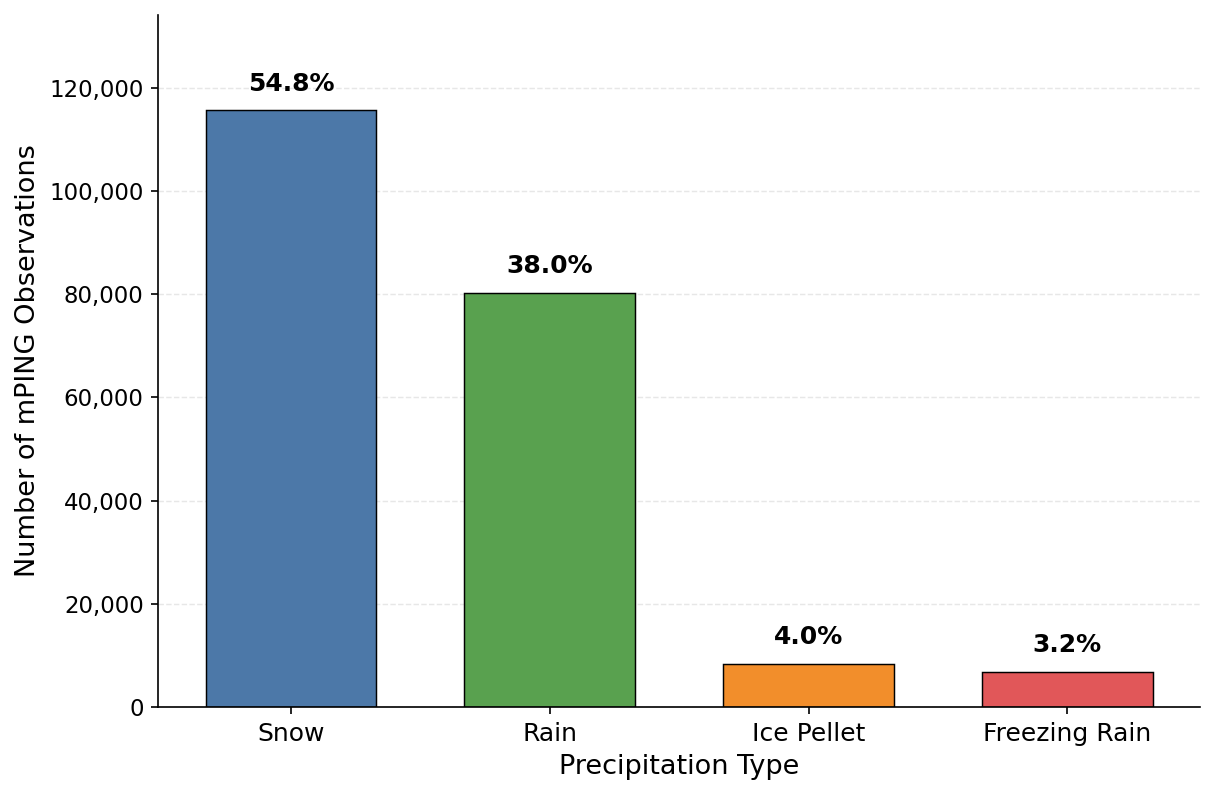

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ============================================================
# Keep observations with >= 70% mPING consensus
# ============================================================
CONSENSUS_THRESHOLD = 70

mping_verified = mping[
    mping["obs_consensus"] >= CONSENSUS_THRESHOLD
].copy()

# Desired class order
class_order = [
    "Snow",
    "Rain",
    "Ice Pellet",
    "Freezing Rain"
]

# ============================================================
# Class distribution
# ============================================================
class_counts = (
    mping_verified["obs_class"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)

class_percent = (
    class_counts / class_counts.sum() * 100
)

# Summary table
summary = pd.DataFrame({
    "Observations": class_counts,
    "Percent": class_percent.round(2)
})

display(summary)

print(f"Total observations before filtering: {len(mping):,}")
print(f"Retained observations: {len(mping_verified):,}")
print(
    f"Retained fraction: "
    f"{100 * len(mping_verified) / len(mping):.2f}%"
)

# ============================================================
# Publication-quality plot
# ============================================================
fig, ax = plt.subplots(figsize=(8.2, 5.4), dpi=150)

colors = [
    "#4C78A8",   # Snow
    "#59A14F",   # Rain
    "#F28E2B",   # Ice Pellet
    "#E15759"    # Freezing Rain
]

bars = ax.bar(
    class_order,
    class_counts.values,
    width=0.66,
    color=colors,
    edgecolor="black",
    linewidth=0.7
)

# ------------------------------------------------------------
# Percentage labels above bars
# ------------------------------------------------------------
ymax = class_counts.max()

for bar, pct in zip(bars, class_percent):
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.025 * ymax,
        f"{pct:.1f}%",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------
ax.set_ylabel(
    "Number of mPING Observations",
    fontsize=13
)

ax.set_xlabel(
    "Precipitation Type",
    fontsize=13
)

# ax.set_title(
#     "Distribution of mPING Precipitation-Type Observations",
#     fontsize=15,
#     fontweight="bold",
#     pad=14
# )

# Subtitle / filtering information
# ax.text(
#     0.5,
#     1.01,
#     f"Consensus ≥ {CONSENSUS_THRESHOLD}%  |  "
#     f"N = {len(mping_verified):,}  |  "
#     f"24 Nov 2021 – 31 Mar 2022",
#     transform=ax.transAxes,
#     ha="center",
#     va="bottom",
#     fontsize=10.5,
#     color="0.35"
# )

# Format y-axis with commas
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{int(x):,}")
)

# Grid
ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.30
)

ax.set_axisbelow(True)

# Clean publication-style frame
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="x",
    labelsize=12
)

ax.tick_params(
    axis="y",
    labelsize=11
)

# Give labels some vertical room
ax.set_ylim(0, ymax * 1.16)

plt.tight_layout()

# # High-resolution output
# plt.savefig(
#     "mping_class_distribution_consensus70.png",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()

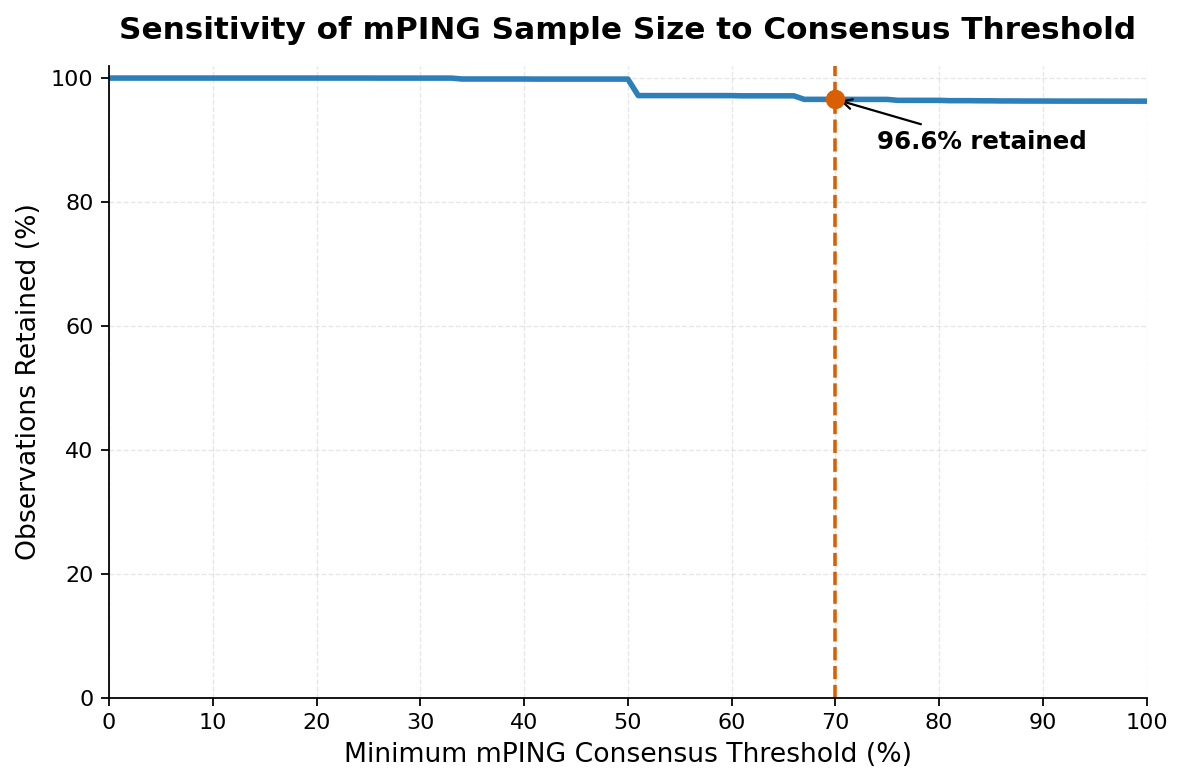

In [28]:
import numpy as np
import matplotlib.pyplot as plt

# Consensus values
consensus = mping["obs_consensus"].dropna()

# Thresholds from 0 to 100%
thresholds = np.arange(0, 101, 1)

# Fraction of observations retained at each threshold
retained = np.array([
    (consensus >= t).mean() * 100
    for t in thresholds
])

# Value at 70%
threshold = 70
retained_70 = (consensus >= threshold).mean() * 100

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(7.5, 5.0), dpi=160)

ax.plot(
    thresholds,
    retained,
    linewidth=2.5,
    color="#2C7FB8"
)

# 70% threshold
ax.axvline(
    threshold,
    linestyle="--",
    linewidth=1.6,
    color="#D95F02"
)

# Mark the actual retained fraction
ax.scatter(
    threshold,
    retained_70,
    s=60,
    color="#D95F02",
    zorder=5
)

ax.annotate(
    f"{retained_70:.1f}% retained",
    xy=(threshold, retained_70),
    xytext=(74, retained_70 - 8),
    fontsize=11,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="->",
        linewidth=1.0
    )
)

# Formatting
ax.set_xlabel("Minimum mPING Consensus Threshold (%)", fontsize=12)
ax.set_ylabel("Observations Retained (%)", fontsize=12)

ax.set_title(
    "Sensitivity of mPING Sample Size to Consensus Threshold",
    fontsize=14,
    fontweight="bold",
    pad=12
)

ax.set_xlim(0, 100)
ax.set_ylim(0, 102)

ax.set_xticks(np.arange(0, 101, 10))
ax.set_yticks(np.arange(0, 101, 20))

ax.grid(
    linestyle="--",
    linewidth=0.6,
    alpha=0.3
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()



plt.show()

In [31]:
# For the case study spatial plot


target_time = pd.Timestamp("2022-02-03 18:00:00")

obs_18z = mping[mping["datetime"] == target_time]

print("Number of processed observations:", len(obs_18z))
print("Total underlying mPING reports:", obs_18z["report_count"].sum())

Number of processed observations: 590
Total underlying mPING reports: 832


In [32]:
obs_18z_verified = mping[
    (mping["datetime"] == target_time) &
    (mping["obs_consensus"] >= 70)
]

print("Verified observations:", len(obs_18z_verified))
print("Underlying reports:", obs_18z_verified["report_count"].sum())

Verified observations: 536
Underlying reports: 696
